<a href="https://colab.research.google.com/github/Shahnazain/AIML-Lab/blob/main/lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#LOGISTIC REGRESSION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import ipywidgets as widgets
from IPython.display import display, clear_output


In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFuncti

In [ ]:
features_with_invalid_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[features_with_invalid_zero] = df[features_with_invalid_zero].replace(
    0, np.nan
)

print("Missing values after treating invalid zeros:")
print(df.isnull().sum())



for column in features_with_invalid_zero:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after median imputation:")
print(df.isnull().sum())


Missing values after treating invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("0 = No diabetes")
print("1 = Diabetes")


Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
0 = No diabetes
1 = Diabetes


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


Training samples: 614
Testing samples : 154


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test_scaled)

y_probability = model.predict_proba(X_test_scaled)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 probabilities:")
print(y_probability[:10])


First 10 predictions:
[1 0 0 0 0 0 0 1 0 1]

First 10 probabilities:
[0.60971073 0.11835576 0.29346313 0.2508367  0.03320667 0.16852385
 0.4881643  0.92367511 0.08143405 0.8385896 ]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===================================")
print("     MODEL PERFORMANCE")
print("===================================")

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score  : {f1:.4f} ({f1*100:.2f}%)")


     MODEL PERFORMANCE
Accuracy  : 0.7078 (70.78%)
Precision : 0.6000 (60.00%)
Recall    : 0.5000 (50.00%)
F1 Score  : 0.5455 (54.55%)


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))


              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



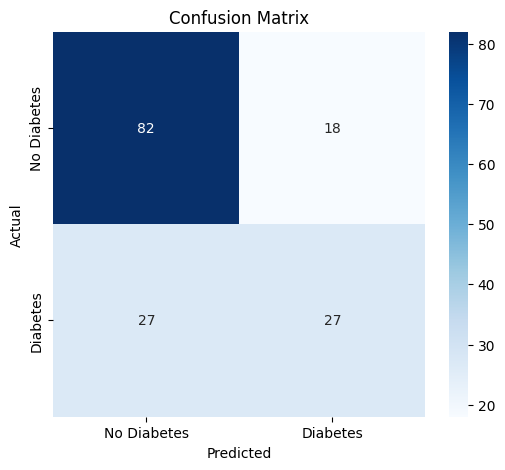

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


In [ ]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients


,Feature,Coefficient
1,Glucose,1.182511
5,BMI,0.688735
0,Pregnancies,0.377502
6,DiabetesPedigreeFunction,0.233386
7,Age,0.147798
3,SkinThickness,0.028225
2,BloodPressure,-0.044066
4,Insulin,-0.066157


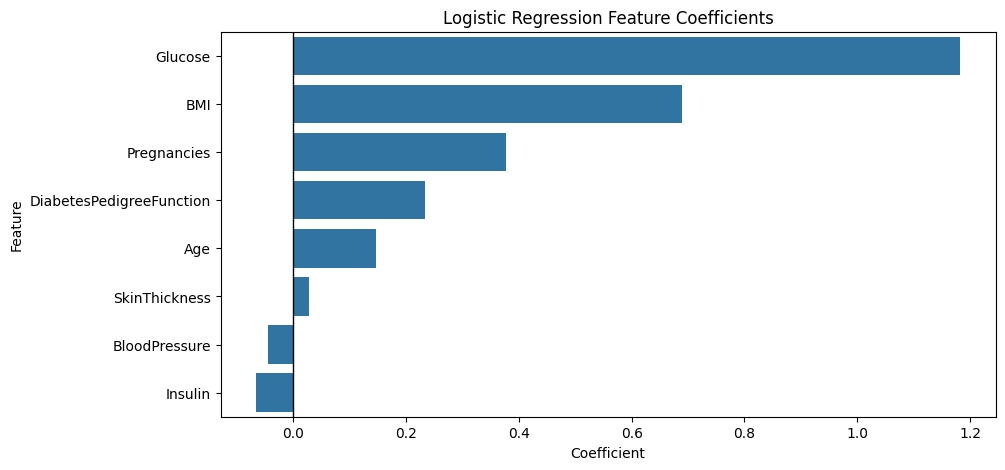

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Coefficients")
plt.axvline(0, color="black", linewidth=1)

plt.show()


In [ ]:
# Create input widgets

pregnancies = widgets.FloatText(
    value=1,
    description="Pregnancies:"
)

glucose = widgets.FloatText(
    value=120,
    description="Glucose:"
)

blood_pressure = widgets.FloatText(
    value=70,
    description="Blood Pressure:"
)

skin_thickness = widgets.FloatText(
    value=20,
    description="Skin Thickness:"
)

insulin = widgets.FloatText(
    value=79,
    description="Insulin:"
)

bmi = widgets.FloatText(
    value=30,
    description="BMI:"
)

diabetes_pedigree = widgets.FloatText(
    value=0.5,
    description="Pedigree:"
)

age = widgets.FloatText(
    value=30,
    description="Age:"
)

predict_button = widgets.Button(
    description="Predict",
    button_style="success",
    icon="check"
)

output = widgets.Output()




def predict_diabetes(button):

    with output:
        clear_output()

        # Collect user input
        user_data = pd.DataFrame([{
            "Pregnancies": pregnancies.value,
            "Glucose": glucose.value,
            "BloodPressure": blood_pressure.value,
            "SkinThickness": skin_thickness.value,
            "Insulin": insulin.value,
            "BMI": bmi.value,
            "DiabetesPedigreeFunction": diabetes_pedigree.value,
            "Age": age.value
        }])

        # Scale using the scaler trained on training data
        user_data_scaled = scaler.transform(user_data)

        # Prediction
        prediction = model.predict(user_data_scaled)[0]

        # Probability
        probability = model.predict_proba(
            user_data_scaled
        )[0][1]

        print("=" * 50)
        print("          DIABETES PREDICTION")
        print("=" * 50)

        print(f"\nProbability of diabetes: {probability * 100:.2f}%")

        if prediction == 1:
            print("\nPrediction: TRUE")
            print("The model predicts: DIABETES")
        else:
            print("\nPrediction: FALSE")
            print("The model predicts: NO DIABETES")

        print("=" * 50)


In [ ]:
predict_button.on_click(predict_diabetes)


In [ ]:
ui = widgets.VBox([
    widgets.HTML("<h2>Diabetes Prediction System</h2>"),
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age,
    predict_button,
    output
])

display(ui)
